In [27]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset/UNSW_NB15_testing-set.csv
/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset/UNSW_NB15_training-set.csv
/kaggle/input/datasets/uzairsidd/cybersentry-models/threshold.joblib
/kaggle/input/datasets/uzairsidd/cybersentry-models/xgboost_model.joblib


# CyberSentryFusion — Model Explainability

## Objective

Understand how the trained XGBoost model makes network intrusion detection predictions using SHAP (SHapley Additive exPlanations).

## Goals

1. Identify the features that most influence attack detection.
2. Visualize global feature importance.
3. Understand how individual features affect predictions.
4. Explain individual network traffic predictions.

## Model

The trained XGBoost pipeline uses the UNSW-NB15 dataset to classify network traffic as **Normal** or **Attack**.

**Note:** This notebook explains the previously trained model. It does not retrain the model.


In [28]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [29]:
import os
import joblib
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")
print("SHAP version:", shap.__version__)

All libraries imported successfully!
SHAP version: 0.52.0


In [30]:
import os

for path in ["/kaggle/input", "/kaggle/working"]:
    print(f"\nContents of {path}:")
    print(os.listdir(path))


Contents of /kaggle/input:
['datasets']

Contents of /kaggle/working:
['.virtual_documents']


In [31]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(f"\n {root}")
    for file in files:
        print(f"   📄 {file}")


 /kaggle/input

 /kaggle/input/datasets

 /kaggle/input/datasets/uzairsidd

 /kaggle/input/datasets/uzairsidd/cyber-sentry-dataset
   📄 UNSW_NB15_testing-set.csv
   📄 UNSW_NB15_training-set.csv

 /kaggle/input/datasets/uzairsidd/cybersentry-models
   📄 threshold.joblib
   📄 xgboost_model.joblib


In [32]:
# Paths to the saved model files
model_path = "/kaggle/input/datasets/uzairsidd/cybersentry-models/xgboost_model.joblib"
threshold_path = "/kaggle/input/datasets/uzairsidd/cybersentry-models/threshold.joblib"

# Load the trained model and decision threshold
model = joblib.load(model_path)
threshold = joblib.load(threshold_path)

print("Model loaded successfully!")
print("Model type:", type(model))
print("Decision threshold:", threshold)

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
Decision threshold: 0.5


In [33]:
# Display the pipeline structure
model


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['dur', 'spkts', 'dpkts',
                                                   'sbytes', 'dbytes', 'rate',
                                                   'sttl', 'dttl', 'sload',
                                                   'dload', 'sloss', 'dloss',
                                                   'sinpkt', 'dinpkt', 'sjit',
                                                   'djit', 'swin', 'stcpb',
                                                   'dtcpb', 'dwin', 'tcprtt',
                                                   'synack', 'ackdat', 'smean',
                                                   'dmean', 'trans_depth',
                                                   'response_body_len',
                                                   'ct_srv_src', 'ct_state_ttl',
                                                   '...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [34]:
print(model.named_steps)

{'preprocessor': ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes',
                                  'rate', 'sttl', 'dttl', 'sload', 'dload',
                                  'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit',
                                  'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
                                  'tcprtt', 'synack', 'ackdat', 'smean',
                                  'dmean', 'trans_depth', 'response_body_len',
                                  'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', ...]),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['proto', 'service', 'state'])]), 'classifier': XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              en

In [35]:
# Dataset paths
train_path = "/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset/UNSW_NB15_training-set.csv"
test_path = "/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset/UNSW_NB15_testing-set.csv"

# Load datasets
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

# Separate features and target
X_train = train_df.drop(columns=["label", "attack_cat", "id"])
y_train = train_df["label"]

X_test = test_df.drop(columns=["label", "attack_cat", "id"])
y_test = test_df["label"]

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("\nTraining columns match testing columns:", 
      list(X_train.columns) == list(X_test.columns))

Training features shape: (175341, 42)
Testing features shape: (82332, 42)

Training columns match testing columns: True


In [36]:
# Extract the trained preprocessing and classification steps
preprocessor = model.named_steps["preprocessor"]
xgb_model = model.named_steps["classifier"]

# Transform a sample of the training data
X_sample = X_train.sample(n=1000, random_state=42)
X_sample_transformed = preprocessor.transform(X_sample)

print("Original sample shape:", X_sample.shape)
print("Transformed sample shape:", X_sample_transformed.shape)
print("XGBoost classifier:", type(xgb_model).__name__)

Original sample shape: (1000, 42)
Transformed sample shape: (1000, 194)
XGBoost classifier: XGBClassifier


In [37]:
# Get the names of the transformed features
feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))
print("First 10 feature names:")
print(feature_names[:10])

Number of feature names: 194
First 10 feature names:
['num__dur' 'num__spkts' 'num__dpkts' 'num__sbytes' 'num__dbytes'
 'num__rate' 'num__sttl' 'num__dttl' 'num__sload' 'num__dload']


In [38]:
# Convert the sparse matrix to a dense array
X_sample_dense = X_sample_transformed.toarray()

# Create a DataFrame with the correct feature names
X_sample_transformed_df = pd.DataFrame(
    X_sample_dense,
    columns=feature_names,
    index=X_sample.index
)

print("Transformed DataFrame shape:", X_sample_transformed_df.shape)
print("\nFirst 5 feature names:")
print(X_sample_transformed_df.columns[:5].tolist())

print("\nFirst 5 rows:")
display(X_sample_transformed_df.head())

Transformed DataFrame shape: (1000, 194)

First 5 feature names:
['num__dur', 'num__spkts', 'num__dpkts', 'num__sbytes', 'num__dbytes']

First 5 rows:


,num__dur,num__spkts,num__dpkts,num__sbytes,num__dbytes,num__rate,num__sttl,num__dttl,num__sload,num__dload,...,cat__service_ssl,cat__state_CON,cat__state_ECO,cat__state_FIN,cat__state_INT,cat__state_PAR,cat__state_REQ,cat__state_RST,cat__state_URN,cat__state_no
15482,0.212535,1.546539,3.800455,0.025778,3.712307,-0.575341,-1.443048,-0.457978,-0.389766,0.383148,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
133349,-0.209773,-0.133677,-0.172047,-0.049958,-0.103923,0.094951,0.723268,-0.720406,-0.120980,-0.277208,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
80485,0.683485,0.114703,0.136320,-0.015694,-0.076830,-0.576747,0.723268,1.560002,-0.389929,-0.275052,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
29972,0.384283,3.124480,7.609704,0.093355,7.517093,-0.574770,-1.443048,-0.457978,-0.389696,0.661315,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
18339,-0.209612,-0.133677,-0.153908,-0.049866,-0.102795,-0.559578,-1.443048,-0.457978,-0.387348,-0.022812,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [39]:
print("Transformed object type:", type(X_sample_transformed))
print("Transformed shape:", X_sample_transformed.shape)

print("\nFeature names count:", len(feature_names))

Transformed object type: <class 'scipy.sparse._csr.csr_matrix'>
Transformed shape: (1000, 194)

Feature names count: 194


In [40]:
# Create a SHAP TreeExplainer for the trained XGBoost classifier
explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully!")

# Calculate SHAP values for the sample
shap_values = explainer(X_sample_transformed_df)

print("SHAP values calculated successfully!")
print("SHAP values shape:", shap_values.values.shape)

SHAP explainer created successfully!
SHAP values calculated successfully!
SHAP values shape: (1000, 194)


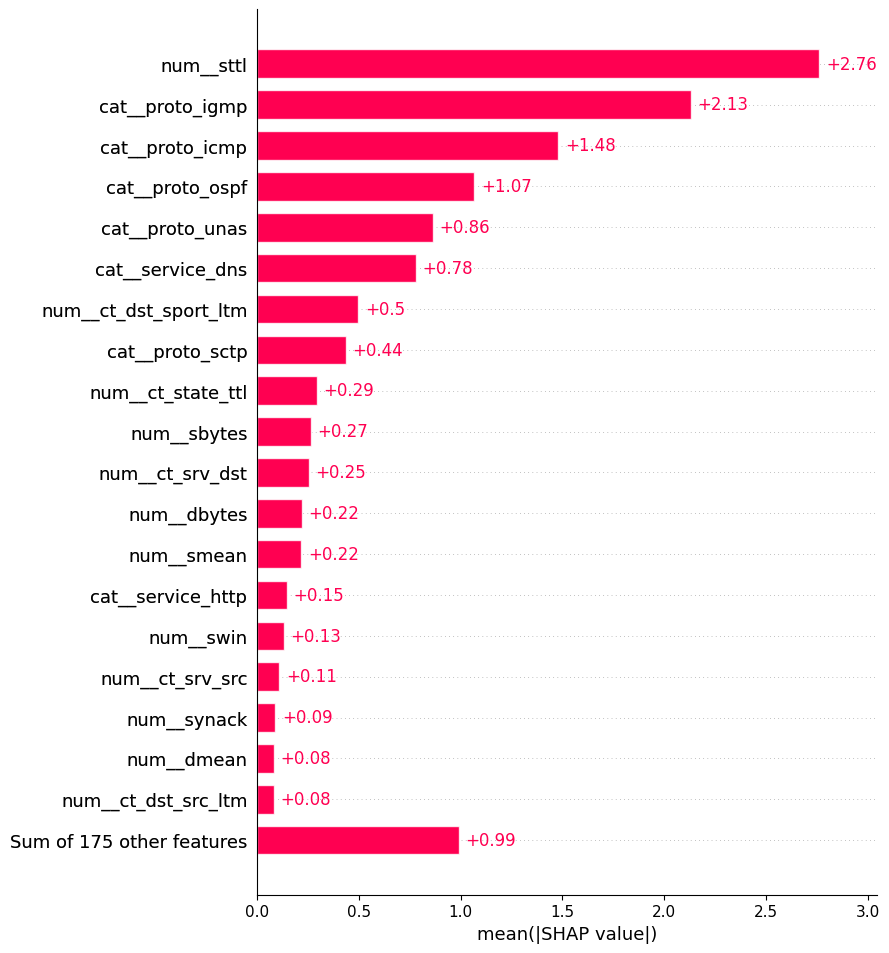

In [41]:
# Plot global feature importance using SHAP
shap.plots.bar(shap_values, max_display=20)

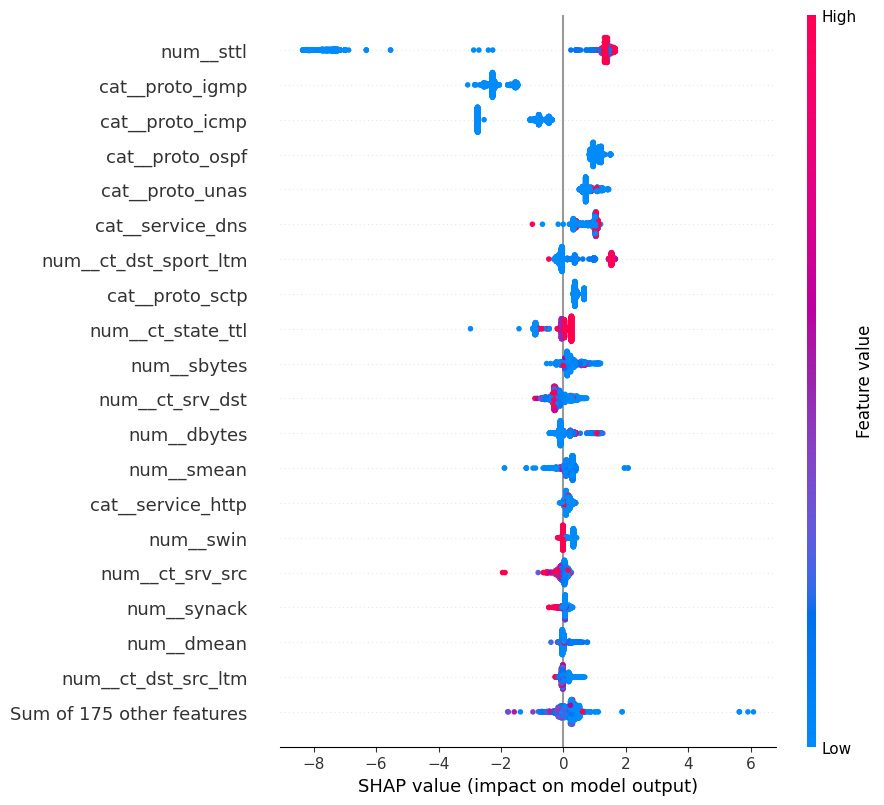

In [42]:
shap.plots.beeswarm(shap_values, max_display=20)

In [43]:
# Select one sample from the SHAP dataset
sample_idx = 0

# Display the model's predicted attack probability
sample = X_sample.iloc[[sample_idx]]

attack_probability = model.predict_proba(sample)[0][1]
prediction = int(attack_probability >= threshold)

print("Predicted class:", "Attack" if prediction == 1 else "Normal")
print(f"Attack probability: {attack_probability:.4f}")
print("Decision threshold:", threshold)

Predicted class: Normal
Attack probability: 0.0001
Decision threshold: 0.5


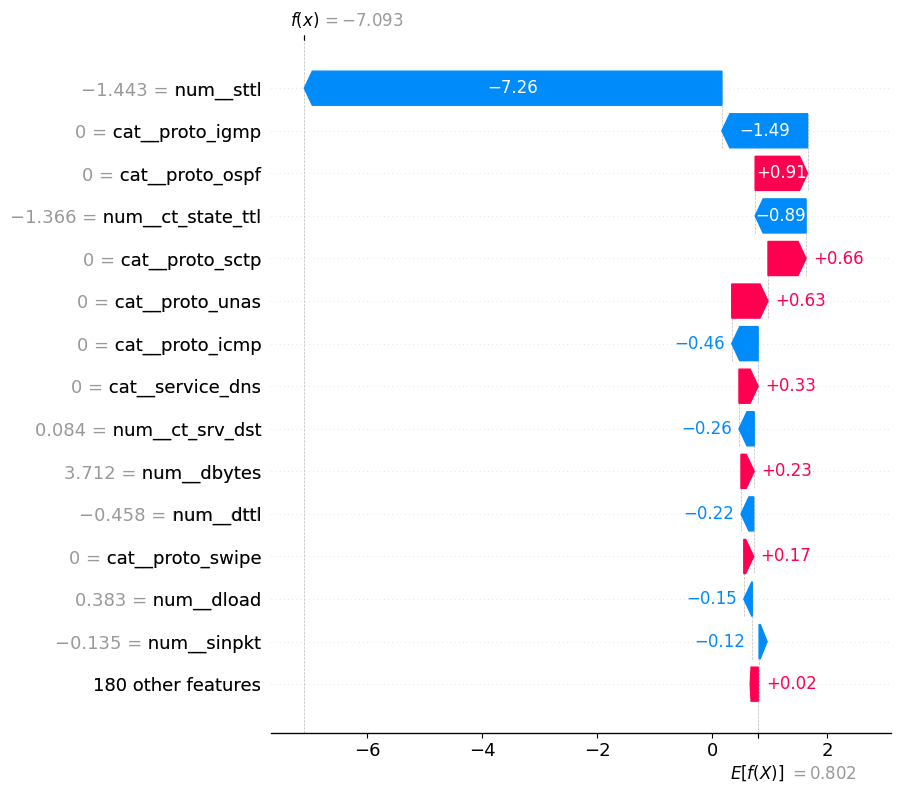

In [44]:
# Get SHAP values for the selected sample
sample_shap = shap_values[sample_idx]

# Plot how features contribute to this prediction
shap.plots.waterfall(sample_shap, max_display=15)

In [45]:
# Compare the model's actual probability with SHAP's raw output
actual_probability = model.predict_proba(X_sample.iloc[[sample_idx]])[0][1]

shap_raw_output = float(shap_values[sample_idx].base_values)
shap_raw_output += float(shap_values[sample_idx].values.sum())

probability_from_shap = 1 / (1 + np.exp(-shap_raw_output))

print(f"Model attack probability:       {actual_probability:.6f}")
print(f"SHAP reconstructed raw output:  {shap_raw_output:.6f}")
print(f"Probability from SHAP output:   {probability_from_shap:.6f}")


Model attack probability:       0.000135
SHAP reconstructed raw output:  -7.092617
Probability from SHAP output:   0.000831


In [46]:
# Select the same sample
sample = X_sample.iloc[[sample_idx]]

# Transform it using the saved preprocessing pipeline
sample_transformed = preprocessor.transform(sample)

# Get probabilities from the complete pipeline
pipeline_probability = model.predict_proba(sample)[0][1]

# Get probabilities directly from the XGBoost classifier
xgb_probability = xgb_model.predict_proba(sample_transformed)[0][1]

# Get XGBoost's raw margin (log-odds)
xgb_raw_margin = xgb_model.predict(
    sample_transformed,
    output_margin=True
)[0]

print(f"Pipeline attack probability: {pipeline_probability:.8f}")
print(f"XGBoost attack probability:  {xgb_probability:.8f}")
print(f"XGBoost raw margin:         {xgb_raw_margin:.6f}")
print(f"SHAP reconstructed output:  {shap_raw_output:.6f}")

Pipeline attack probability: 0.00013452
XGBoost attack probability:  0.00013452
XGBoost raw margin:         -8.913677
SHAP reconstructed output:  -7.092617


In [47]:
print("Explainer model output:", explainer.model.model_output)
print("Explainer feature perturbation:", explainer.feature_perturbation)
print("SHAP base value:", shap_values[sample_idx].base_values)
print("Sum of SHAP values:", shap_values[sample_idx].values.sum())
print("XGBoost raw margin:", xgb_raw_margin)

Explainer model output: raw
Explainer feature perturbation: tree_path_dependent
SHAP base value: 0.8021091
Sum of SHAP values: -7.894726
XGBoost raw margin: -8.913677


In [48]:
# Recreate the explainer explicitly for raw XGBoost output
explainer = shap.TreeExplainer(
    xgb_model,
    data=None,
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

# Recalculate SHAP values for the same sample
single_sample_transformed = X_sample_transformed_df.iloc[[sample_idx]]
single_sample_shap = explainer(single_sample_transformed)

# Compare reconstructed output with XGBoost's actual raw margin
shap_reconstructed = (
    float(single_sample_shap.base_values[0])
    + float(single_sample_shap.values[0].sum())
)

print(f"SHAP reconstructed raw output: {shap_reconstructed:.6f}")
print(f"XGBoost actual raw margin:     {xgb_raw_margin:.6f}")
print(f"Absolute difference:           {abs(shap_reconstructed - xgb_raw_margin):.6f}")

SHAP reconstructed raw output: -7.092617
XGBoost actual raw margin:     -8.913677
Absolute difference:           1.821061


In [49]:
# Inspect the XGBoost model configuration
print("XGBoost feature count:", xgb_model.n_features_in_)

print("Transformed sample shape:", X_sample_transformed_df.shape)

print("\nXGBoost feature types:")
print(xgb_model.get_booster().feature_types)

print("\nXGBoost booster feature names:")
print(xgb_model.get_booster().feature_names)

XGBoost feature count: 194
Transformed sample shape: (1000, 194)

XGBoost feature types:
None

XGBoost booster feature names:
None


In [50]:
# Create an explainer directly from the XGBoost booster
booster = xgb_model.get_booster()

booster_explainer = shap.TreeExplainer(
    booster,
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

# Explain one transformed sample
sample_array = X_sample_transformed_df.iloc[[sample_idx]].to_numpy()
booster_shap = booster_explainer(sample_array)

# Reconstruct the raw output
booster_shap_output = (
    float(booster_shap.base_values[0])
    + float(booster_shap.values[0].sum())
)

print(f"Booster SHAP output: {booster_shap_output:.6f}")
print(f"Actual XGBoost margin: {xgb_raw_margin:.6f}")
print(f"Absolute difference: {abs(booster_shap_output - xgb_raw_margin):.6f}")

Booster SHAP output: -7.092617
Actual XGBoost margin: -8.913677
Absolute difference: 1.821061


In [51]:
# Get the raw XGBoost prediction through its native API
import xgboost as xgb

sample_array = X_sample_transformed_df.iloc[[sample_idx]].to_numpy()

dmatrix = xgb.DMatrix(sample_array)
native_margin = booster.predict(dmatrix, output_margin=True)[0]

# Compare native and sklearn predictions
sklearn_margin = xgb_model.predict(
    sample_array,
    output_margin=True
)[0]

print(f"Native XGBoost margin: {native_margin:.6f}")
print(f"Sklearn XGBoost margin: {sklearn_margin:.6f}")
print(f"SHAP reconstructed output: {booster_shap_output:.6f}")

Native XGBoost margin: -7.092616
Sklearn XGBoost margin: -7.092616
SHAP reconstructed output: -7.092617


In [52]:
# Verify the sample prediction using the same transformed data

sample_array = X_sample_transformed_df.iloc[[sample_idx]].to_numpy()

raw_margin = xgb_model.predict(
    sample_array,
    output_margin=True
)[0]

attack_probability = xgb_model.predict_proba(sample_array)[0, 1]

print(f"Raw margin: {raw_margin:.6f}")
print(f"Attack probability: {attack_probability:.8f}")
print(f"Probability from sigmoid: {1 / (1 + np.exp(-raw_margin)):.8f}")

Raw margin: -7.092616
Attack probability: 0.00083053
Probability from sigmoid: 0.00083053


In [53]:
# Verify SHAP additivity for the selected sample

shap_base = float(booster_shap.base_values[0])
shap_contributions = float(booster_shap.values[0].sum())
shap_reconstructed = shap_base + shap_contributions

print(f"SHAP base value:       {shap_base:.6f}")
print(f"Sum of contributions:  {shap_contributions:.6f}")
print(f"Reconstructed margin:  {shap_reconstructed:.6f}")
print(f"Actual raw margin:     {raw_margin:.6f}")
print(f"Absolute difference:   {abs(shap_reconstructed - raw_margin):.8f}")

SHAP base value:       0.802109
Sum of contributions:  -7.894726
Reconstructed margin:  -7.092617
Actual raw margin:     -7.092616
Absolute difference:   0.00000095


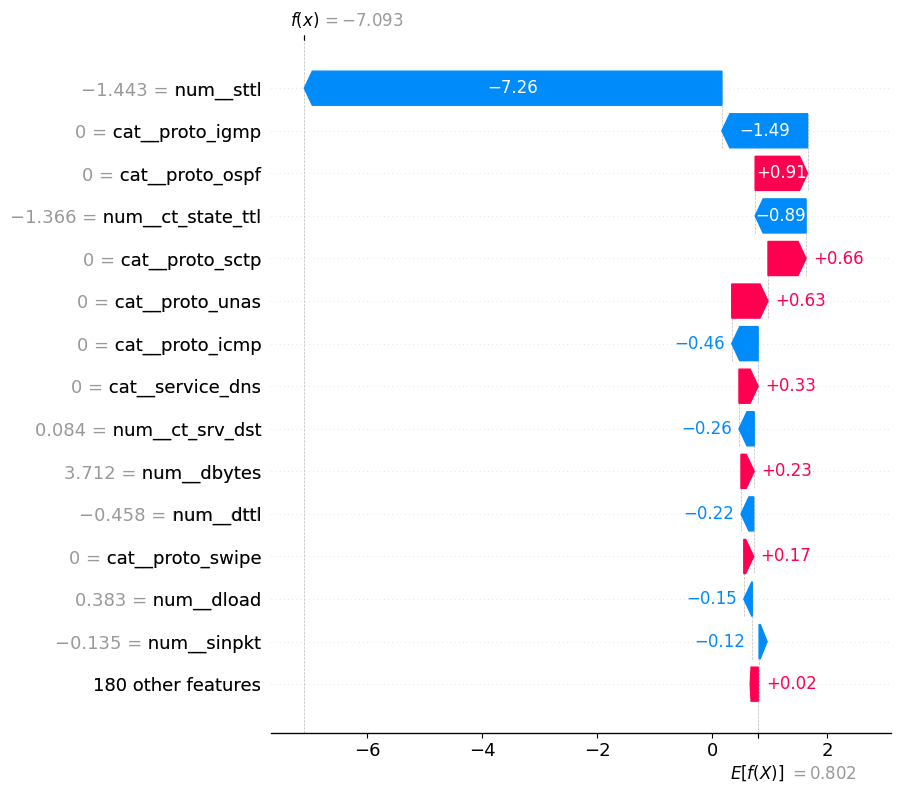

In [54]:
# Create a verified SHAP explanation for the selected sample

verified_explanation = shap.Explanation(
    values=booster_shap.values[0],
    base_values=booster_shap.base_values[0],
    data=sample_array[0],
    feature_names=feature_names
)

shap.plots.waterfall(
    verified_explanation,
    max_display=15
)

In [55]:
# Find samples predicted as attacks

sample_probabilities = xgb_model.predict_proba(
    X_sample_transformed_df
)[:, 1]

attack_indices = np.where(sample_probabilities >= threshold)[0]

print("Number of predicted attacks:", len(attack_indices))

if len(attack_indices) > 0:
    attack_idx = attack_indices[0]

    print("Selected sample index:", attack_idx)
    print(f"Attack probability: {sample_probabilities[attack_idx]:.4f}")
    print("Predicted class: Attack")
else:
    print("No attack predictions found in this sample.")

Number of predicted attacks: 763
Selected sample index: 1
Attack probability: 0.9436
Predicted class: Attack


In [56]:
# Generate SHAP values for the selected attack sample

attack_shap = booster_explainer(
    X_sample_transformed_df.iloc[[attack_idx]].to_numpy()
)

# Verify SHAP additivity
attack_margin = xgb_model.predict(
    X_sample_transformed_df.iloc[[attack_idx]].to_numpy(),
    output_margin=True
)[0]

reconstructed_margin = (
    float(attack_shap.base_values[0])
    + float(attack_shap.values[0].sum())
)

print(f"Attack probability: {sample_probabilities[attack_idx]:.4f}")
print(f"Actual raw margin: {attack_margin:.6f}")
print(f"SHAP reconstructed margin: {reconstructed_margin:.6f}")
print(
    "Absolute difference:",
    f"{abs(attack_margin - reconstructed_margin):.8f}"
)

Attack probability: 0.9436
Actual raw margin: 2.816318
SHAP reconstructed margin: 2.816318
Absolute difference: 0.00000000


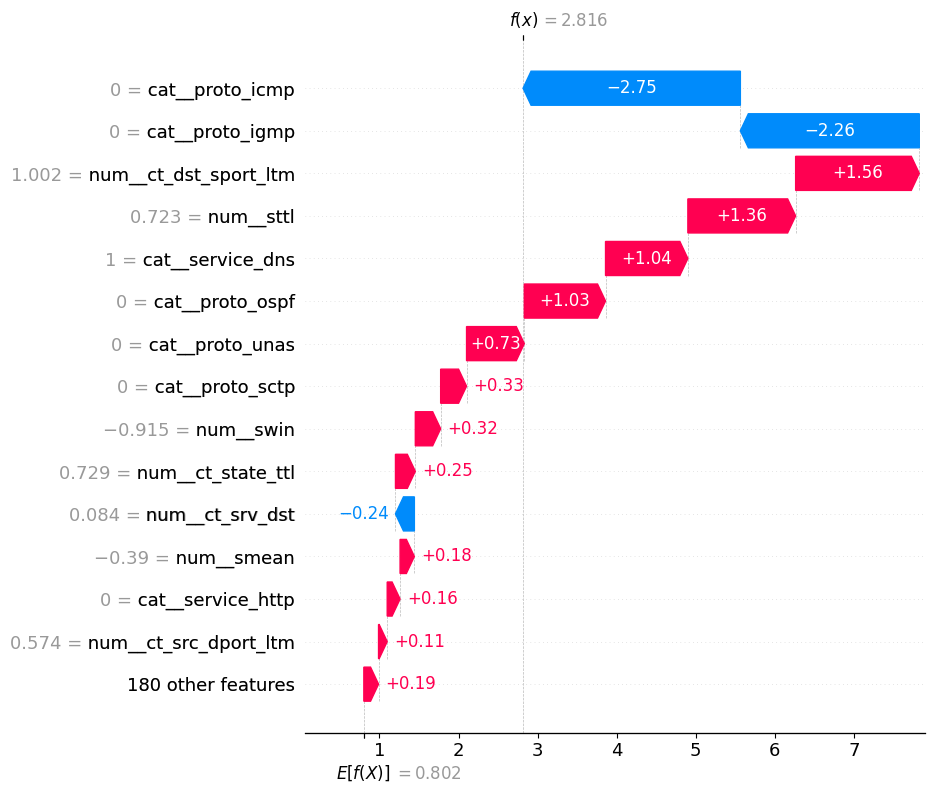

In [57]:
# Create a SHAP explanation for the selected attack sample

attack_explanation = shap.Explanation(
    values=attack_shap.values[0],
    base_values=attack_shap.base_values[0],
    data=X_sample_transformed_df.iloc[attack_idx].to_numpy(),
    feature_names=feature_names
)

shap.plots.waterfall(
    attack_explanation,
    max_display=15
)

In [58]:
# Compare the Normal and Attack samples

normal_idx = sample_idx

normal_probability = sample_probabilities[normal_idx]
attack_probability = sample_probabilities[attack_idx]

normal_values = booster_shap.values[0]
attack_values = attack_shap.values[0]

normal_top = np.argsort(np.abs(normal_values))[::-1][:10]
attack_top = np.argsort(np.abs(attack_values))[::-1][:10]

comparison = pd.DataFrame({
    "Feature": feature_names,
    "Normal_SHAP": normal_values,
    "Attack_SHAP": attack_values
})

comparison["Normal_Abs_SHAP"] = comparison["Normal_SHAP"].abs()
comparison["Attack_Abs_SHAP"] = comparison["Attack_SHAP"].abs()

print(f"Normal sample attack probability: {normal_probability:.4%}")
print(f"Attack sample attack probability: {attack_probability:.4%}")

print("\nTop features for the Normal sample:")
print(
    comparison.nlargest(10, "Normal_Abs_SHAP")[
        ["Feature", "Normal_SHAP"]
    ].to_string(index=False)
)

print("\nTop features for the Attack sample:")
print(
    comparison.nlargest(10, "Attack_Abs_SHAP")[
        ["Feature", "Attack_SHAP"]
    ].to_string(index=False)
)

Normal sample attack probability: 0.0831%
Attack sample attack probability: 94.3551%

Top features for the Normal sample:
          Feature  Normal_SHAP
        num__sttl    -7.262710
  cat__proto_igmp    -1.490429
  cat__proto_ospf     0.911448
num__ct_state_ttl    -0.885092
  cat__proto_sctp     0.661867
  cat__proto_unas     0.630226
  cat__proto_icmp    -0.458450
 cat__service_dns     0.332845
  num__ct_srv_dst    -0.264627
      num__dbytes     0.229925

Top features for the Attack sample:
              Feature  Attack_SHAP
      cat__proto_icmp    -2.748509
      cat__proto_igmp    -2.263333
num__ct_dst_sport_ltm     1.564152
            num__sttl     1.363245
     cat__service_dns     1.041409
      cat__proto_ospf     1.027580
      cat__proto_unas     0.730409
      cat__proto_sctp     0.327522
            num__swin     0.320592
    num__ct_state_ttl     0.251056


In [59]:

# ==========================================
# CYBERSENTRYFUSION: DEBUG PREDICTION MISMATCH
# ==========================================

import numpy as np
import pandas as pd

# 1. Select one row from our existing sample
sample = X_sample.iloc[[0]]

print("Original sample shape:", sample.shape)

# 2. Get prediction from the COMPLETE pipeline
pipeline_probability = model.predict_proba(sample)[0, 1]

# 3. Transform the SAME row using the pipeline's preprocessor
transformed_sample = preprocessor.transform(sample)

print("Transformed sample shape:", transformed_sample.shape)

# 4. Get prediction directly from XGBoost
direct_probability = xgb_model.predict_proba(transformed_sample)[0, 1]

# 5. Compare predictions
print("\n========== PREDICTION COMPARISON ==========")
print(f"Pipeline attack probability: {pipeline_probability:.10f}")
print(f"Direct XGBoost probability:  {direct_probability:.10f}")
print(f"Absolute difference:        {abs(pipeline_probability - direct_probability):.10f}")

print("\n========== MODEL STRUCTURE ==========")
print("Pipeline steps:", list(model.named_steps.keys()))
print("Preprocessor type:", type(preprocessor).__name__)
print("Classifier type:", type(xgb_model).__name__)

# 6. Check whether the predictions agree
if np.isclose(pipeline_probability, direct_probability, atol=1e-6):
    print("\nRESULT: Predictions agree.")
else:
    print("\nRESULT: Predictions differ. Further investigation is needed.")



Original sample shape: (1, 42)
Transformed sample shape: (1, 194)

========== PREDICTION COMPARISON ==========
Pipeline attack probability: 0.0001345181
Direct XGBoost probability:  0.0001345181
Absolute difference:        0.0000000000

========== MODEL STRUCTURE ==========
Pipeline steps: ['preprocessor', 'classifier']
Preprocessor type: ColumnTransformer
Classifier type: XGBClassifier

RESULT: Predictions agree.


In [60]:
import os

model_dir = "/kaggle/input/datasets/uzairsidd/cybersentry-models"

print("Files available in model directory:")

for filename in os.listdir(model_dir):
    print(filename)

Files available in model directory:
threshold.joblib
xgboost_model.joblib


# CyberSentryFusion — Model Explainability with SHAP

## 1. Objective

The purpose of this notebook is to understand how our trained XGBoost model makes predictions when classifying network traffic as **Normal** or **Attack**.

Although a machine learning model can produce predictions, we also want to understand which features influence those predictions.

We use **Explainable AI (XAI)** and **SHAP** to interpret the model's behaviour.

## 2. Dataset and Model

**Dataset:** UNSW-NB15

The dataset contains network traffic records with numerical and categorical features.

Examples of features include:

* `sttl` — source time-to-live value
* `sbytes` — bytes sent from the source
* `dbytes` — bytes sent to the destination
* `proto` — network protocol
* `service` — network service
* `state` — connection state

The target column `label` indicates whether traffic is Normal (`0`) or Attack (`1`).

Before explainability analysis, we loaded the previously trained model and prepared the input features.

| Dataset  |    Rows | Input features before preprocessing |
| -------- | ------: | ----------------------------------: |
| Training | 175,341 |                                  42 |
| Testing  |  82,332 |                                  42 |

We removed `id`, `attack_cat`, and `label` from the model inputs.

## 3. Preprocessing

The model uses a preprocessing pipeline containing:

* **StandardScaler:** Scales numerical features using statistics learned during training.
* **OneHotEncoder:** Converts categorical features such as `proto`, `service`, and `state` into numerical columns.

The 42 input features become **194 transformed features**.

Examples of transformed feature names include:

* `num__sttl`
* `cat__proto_igmp`
* `cat__proto_icmp`
* `cat__service_dns`

These transformed features are the inputs used by the XGBoost classifier and explained by SHAP.

## 4. What Is SHAP?

**SHAP stands for SHapley Additive exPlanations.**

It is a method for explaining how individual features contribute to a model's prediction.

SHAP assigns each feature a numerical contribution called a SHAP value.

* **Positive SHAP value:** Pushes the model output higher.
* **Negative SHAP value:** Pushes the model output lower.
* **Larger absolute value:** Indicates a larger contribution to that prediction.

Our SHAP explainer uses the model's **raw output (margin)** rather than probability.

The explanation follows this relationship:

`Raw model output = Base value + Sum of SHAP contributions`

The base value is the explainer's reference output. Individual feature contributions explain how the model's output differs from that reference for a particular sample.

SHAP explains the model's learned behaviour; it does not establish that a feature causes an attack.

## 5. Sampling and SHAP Calculation

To make the analysis manageable, we selected 1,000 rows from the training dataset:

```python
X_sample = X_train.sample(n=1000, random_state=42)
```

We transformed these rows using the existing preprocessing pipeline.

The transformed sample had the shape:

`(1000, 194)`

We then created a `TreeExplainer` for the XGBoost classifier and calculated SHAP values.

The resulting explanation contained contributions for 1,000 samples across 194 transformed features.

## 6. Global Feature Importance — SHAP Bar Plot

We generated a bar plot using:

```python
shap.plots.bar(shap_values, max_display=20)
```

For a multi-sample explanation, the standard SHAP bar plot ranks features by their **mean absolute SHAP value**.

This measures the average magnitude of each feature's contribution across the selected samples, without cancelling positive and negative contributions.

Some of the leading features in our plot included:

* `num__sttl`
* `cat__proto_igmp`
* `cat__proto_icmp`
* `cat__proto_ospf`
* `cat__proto_unas`

**Interpretation:** These features had relatively large average absolute contributions to the model's raw output across the selected sample.

The bar plot does not indicate whether a feature generally pushes predictions toward Attack or Normal. The beeswarm plot provides additional information about contribution direction and variation.

## 7. SHAP Beeswarm Plot

We generated a beeswarm plot using:

```python
shap.plots.beeswarm(shap_values, max_display=20)
```

Each dot represents a sample.

* The horizontal position represents its SHAP value.
* Positive values push the raw output higher.
* Negative values push the raw output lower.
* Colour generally indicates whether the feature value is relatively low or high.

For numerical features, the plot helps us examine how different values are associated with the model's output.

For one-hot encoded categorical features, values are generally `0` or `1`.

The beeswarm plot showed that feature contributions vary between samples. For example, `num__sttl` did not have the same contribution for every network connection.

These patterns describe the model's learned relationships, not causal relationships in real network traffic.

## 8. Individual Prediction Explanations — Waterfall Plots

A waterfall plot explains one prediction by showing how individual feature contributions move the raw output away from the base value.

We generated explanations for one Normal prediction and one Attack prediction.

### A. Normal Sample

| Metric                   |     Value |
| ------------------------ | --------: |
| Attack probability       |   0.0831% |
| Raw model output         | -7.092616 |
| Classification threshold |       0.5 |
| Predicted class          |    Normal |

Some of the largest SHAP contributions were:

| Feature             | SHAP value |
| ------------------- | ---------: |
| `num__sttl`         |     -7.263 |
| `cat__proto_igmp`   |     -1.490 |
| `cat__proto_ospf`   |     +0.911 |
| `num__ct_state_ttl` |     -0.885 |
| `cat__proto_sctp`   |     +0.662 |

The largest contribution came from `num__sttl`, which pushed the raw output downward. Other features pushed it upward, but the final output remained strongly negative.

### B. Attack Sample

| Metric                   |     Value |
| ------------------------ | --------: |
| Attack probability       |  94.3551% |
| Raw model output         | +2.816318 |
| Classification threshold |       0.5 |
| Predicted class          |    Attack |

Some of the largest SHAP contributions were:

| Feature                 | SHAP value |
| ----------------------- | ---------: |
| `cat__proto_icmp`       |     -2.749 |
| `cat__proto_igmp`       |     -2.263 |
| `num__ct_dst_sport_ltm` |     +1.564 |
| `num__sttl`             |     +1.363 |
| `cat__service_dns`      |     +1.041 |
| `cat__proto_ospf`       |     +1.028 |

Although some features pushed the output downward, the combined contributions produced a positive raw margin and a high attack probability.

### Key Observation

The same feature can contribute differently to different predictions.

For example, `num__sttl` pushed the Normal sample toward Normal but pushed the Attack sample toward Attack.

Therefore, a feature does not have a fixed positive or negative effect for every sample.

## 9. Raw Margin and Probability

For our binary XGBoost classifier, the raw margin is converted into an attack probability using the sigmoid function:

`Probability = 1 / (1 + exp(-raw_margin))`

For the Normal sample:

* Raw margin: approximately `-7.092616`
* Attack probability: approximately `0.00083053`, or `0.0831%`

For the Attack sample:

* Raw margin: approximately `2.816318`
* Attack probability: approximately `0.943551`, or `94.3551%`

SHAP values in our waterfall plots explain the raw margin, not probability directly.

## 10. Classification Threshold

The saved classification threshold is `0.5`.

The classification rule is:

* If attack probability is at least `0.5`, predict Attack (`1`).
* If attack probability is below `0.5`, predict Normal (`0`).

Thus, the Normal sample was predicted as Normal, while the Attack sample was predicted as Attack.

Changing the threshold changes how probability scores become class predictions. A lower threshold generally detects more potential attacks but can increase false positives.

The best threshold depends on the security requirements and the relative costs of missed attacks and false alarms.

## 11. SHAP Additivity Verification

We checked whether the base value plus the SHAP contributions reconstructs the actual model's raw output.

### Normal Sample

* Reconstructed output: approximately `-7.092617`
* Actual raw margin: approximately `-7.092616`
* Absolute difference: approximately `0.00000095`

### Attack Sample

* Reconstructed output: approximately `2.816318`
* Actual raw margin: approximately `2.816318`
* Absolute difference: approximately `0.00000000`

These negligible differences indicate that SHAP additivity holds for the two examined samples.

This verifies the numerical consistency of the explanations with the selected model outputs. It does not establish that the model is accurate, well-calibrated, free of data leakage, or causally correct.

## 12. Final Achievements

The notebook now contains:

* Loaded model and dataset
* Reused the existing preprocessing pipeline
* Selected a manageable sample for SHAP analysis
* Calculated SHAP values using `TreeExplainer`
* Generated a global feature-importance bar plot
* Generated a beeswarm plot
* Generated a waterfall plot for a Normal prediction
* Generated a waterfall plot for an Attack prediction
* Compared the strongest contributions for both predictions
* Verified SHAP additivity for both samples

## 13. Limitations and Next Steps

The current analysis is a foundation for model explainability, not a complete validation of the cybersecurity system.

Recommended next steps:

1. Evaluate model performance on the held-out test dataset.
2. Check for data leakage and investigate duplicate records.
3. Assess false-positive and false-negative rates.
4. Evaluate probability calibration and the chosen classification threshold.
5. Examine feature importance and explanations on unseen test samples.
6. Improve feature names and document the findings for the project report or dashboard.

### Conclusion

SHAP helps us understand how our trained XGBoost model uses network traffic features when predicting Normal or Attack.

The global plots summarize feature contributions across sampled records, while the waterfall plots explain individual predictions.

Together, these visualizations make the model's behaviour easier to investigate and communicate. They provide useful insight into the model's decisions but do not, by themselves, prove that the predictions are correct or that particular features cause cyberattacks.
